In [ ]:
"""
BCSE331P - Assessment 6: Time Series Analysis (AirPassengers)
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

values = [
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432,
]

In [2]:
# 1. Load
ap = pd.Series(values, index=pd.date_range("1949-01", periods=144, freq="MS"), name="AirPassengers")

In [3]:
# 2. First five and last five observations
print("2. First 5:\n", ap.head(5), "\n")
print("   Last 5:\n", ap.tail(5), "\n")

2. First 5:
 1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: AirPassengers, dtype: int64 

   Last 5:
 1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: AirPassengers, dtype: int64 



In [4]:
# 3. Start and end
print("3. Start:", ap.index[0].strftime("%Y-%m"), "| End:", ap.index[-1].strftime("%Y-%m"), "\n")

3. Start: 1949-01 | End: 1960-12 



In [5]:
# 4. Frequency and characteristics
print("4. Frequency (periods per year): 12  |  inferred freq:", pd.infer_freq(ap.index))
print("   Class:", type(ap).__name__, "| length:", len(ap))
print(ap.describe(), "\n")

4. Frequency (periods per year): 12  |  inferred freq: MS
   Class: Series | length: 144
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: AirPassengers, dtype: float64 



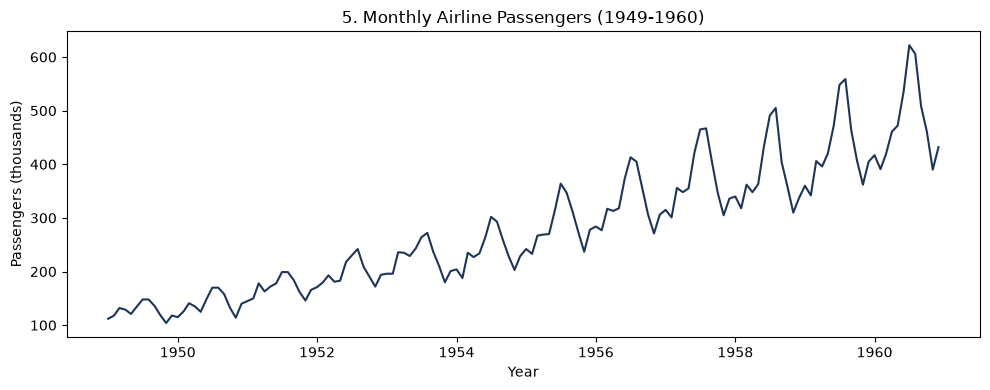

In [6]:
# 5. Trend plot
plt.figure(figsize=(10, 4))
plt.plot(ap, color="#1d3557")
plt.title("5. Monthly Airline Passengers (1949-1960)")
plt.xlabel("Year"); plt.ylabel("Passengers (thousands)")
plt.tight_layout(); plt.show()

In [7]:
# 6. Decompose (multiplicative, as the seasonal swing grows with level)
dec = seasonal_decompose(ap, model="multiplicative", period=12)
print("6. Seasonal indices (first 12 months):\n", dec.seasonal.head(12).round(4), "\n")

6. Seasonal indices (first 12 months):
 1949-01-01    0.9102
1949-02-01    0.8836
1949-03-01    1.0074
1949-04-01    0.9759
1949-05-01    0.9814
1949-06-01    1.1128
1949-07-01    1.2266
1949-08-01    1.2199
1949-09-01    1.0605
1949-10-01    0.9218
1949-11-01    0.8012
1949-12-01    0.8988
Freq: MS, Name: seasonal, dtype: float64 



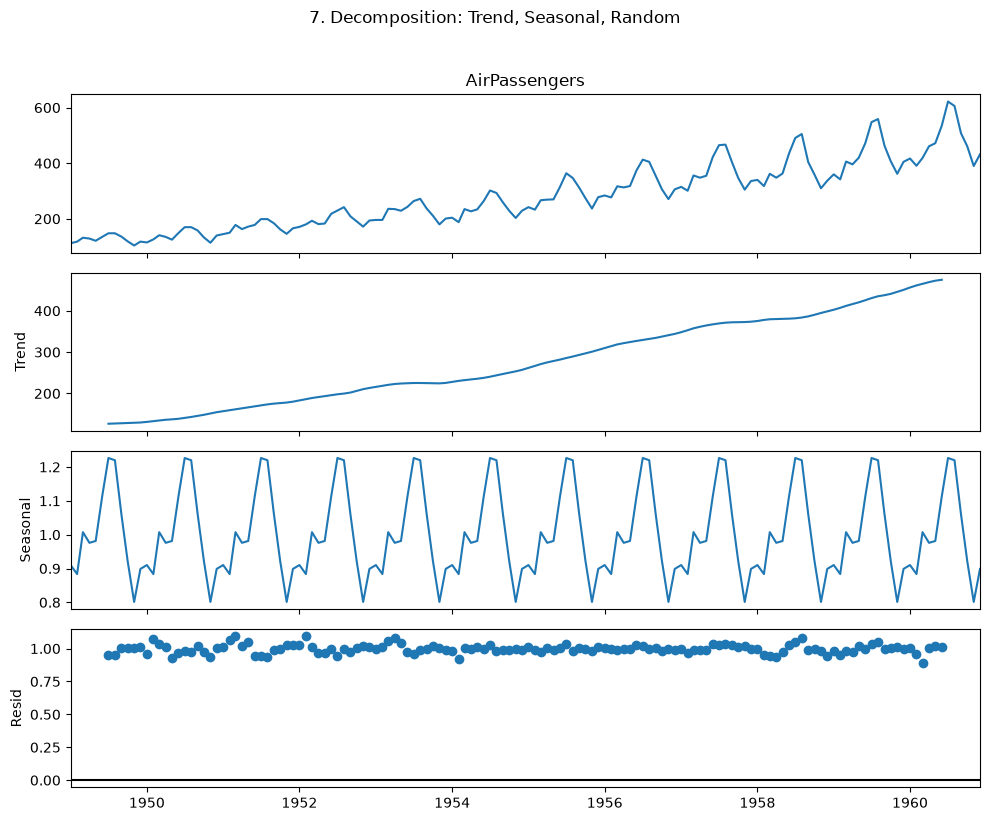

In [8]:
# 7. Plot components
fig = dec.plot()
fig.set_size_inches(10, 8)
fig.suptitle("7. Decomposition: Trend, Seasonal, Random", y=1.02)
plt.tight_layout(); plt.show()

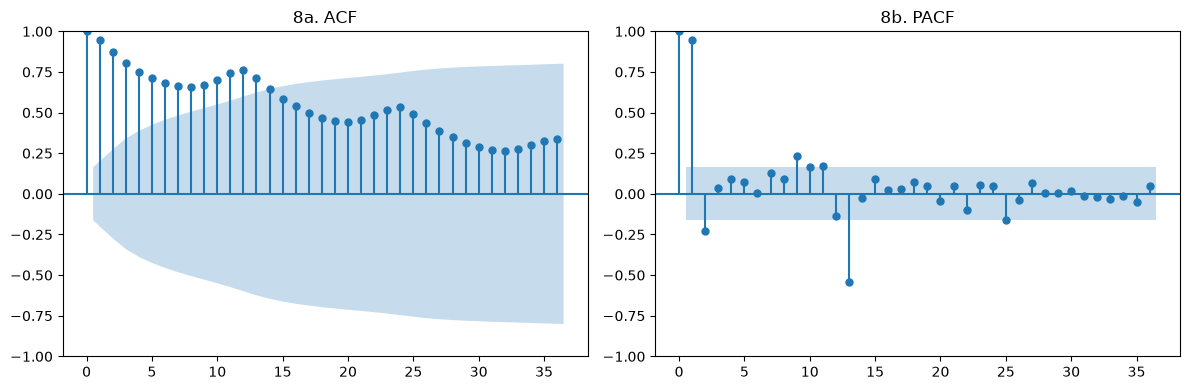

In [9]:
# 8. ACF / PACF
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ap, lags=36, ax=ax[0]); ax[0].set_title("8a. ACF")
plot_pacf(ap, lags=36, ax=ax[1], method="ywm"); ax[1].set_title("8b. PACF")
plt.tight_layout(); plt.show()

In [10]:
# 9. Fit ARIMA - seasonal ARIMA(0,1,1)(0,1,1)[12] on log scale (the classic "airline model")
log_ap = np.log(ap)
model = SARIMAX(log_ap, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
fit = model.fit(disp=False)

In [11]:
# 10. Summary
print("10. Model summary:\n", fit.summary(), "\n")
print("Interpretation: ma.L1 is the non-seasonal MA(1) term and ma.S.L12 the seasonal MA(1) term; "
      "both are negative and significant (p<0.05), meaning shocks are corrected in the next "
      "month / same month next year. Lower AIC = better fit.\n")

10. Model summary:
                                      SARIMAX Results                                      
Dep. Variable:                      AirPassengers   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                            Mon, 19 Oct 2026   AIC                           -483.393
Time:                                    20:34:49   BIC                           -474.767
Sample:                                01-01-1949   HQIC                          -479.888
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4019      0.073     -5.504      0.000      -0.545      -0.259
ma.S.L12      -

In [12]:
# 11. Forecast next 12 months (back-transform from log scale)
fc = fit.get_forecast(steps=12)
fc_mean = np.exp(fc.predicted_mean)
ci = np.exp(fc.conf_int())
print("11. 12-month forecast:\n", pd.DataFrame({"Forecast": fc_mean.round(1),
                                               "Lower95": ci.iloc[:, 0].round(1),
                                               "Upper95": ci.iloc[:, 1].round(1)}), "\n")

11. 12-month forecast:
             Forecast  Lower95  Upper95
1961-01-01     450.4    419.2    484.0
1961-02-01     425.7    391.5    463.0
1961-03-01     479.0    435.9    526.4
1961-04-01     492.4    443.9    546.2
1961-05-01     509.1    455.0    569.5
1961-06-01     583.3    517.3    657.8
1961-07-01     670.0    589.7    761.2
1961-08-01     667.1    583.0    763.3
1961-09-01     558.2    484.6    643.0
1961-10-01     497.2    428.9    576.4
1961-11-01     429.9    368.5    501.4
1961-12-01     477.2    406.7    560.0 



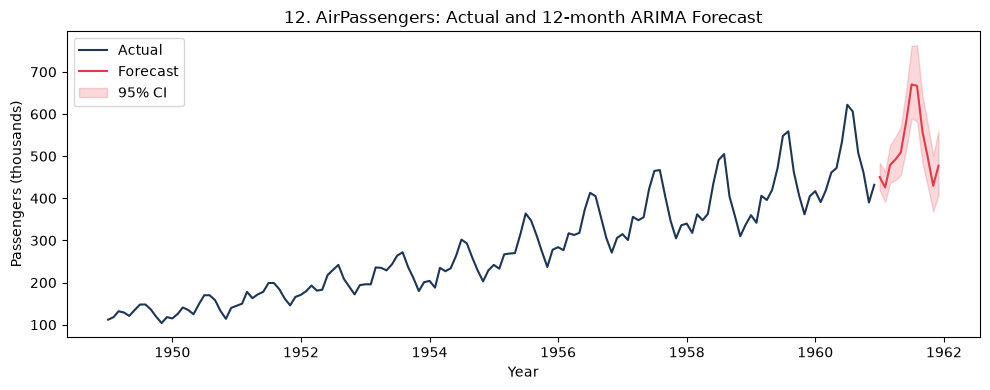

In [13]:
# 12. Actual vs forecast
plt.figure(figsize=(10, 4))
plt.plot(ap, label="Actual", color="#1d3557")
plt.plot(fc_mean, label="Forecast", color="#e63946")
plt.fill_between(fc_mean.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#e63946", alpha=0.2, label="95% CI")
plt.title("12. AirPassengers: Actual and 12-month ARIMA Forecast")
plt.xlabel("Year"); plt.ylabel("Passengers (thousands)"); plt.legend()
plt.tight_layout(); plt.show()